# Modelo 2 · Sismos de todo Santander · Registro del entrenamiento

**UTSmart IA Challenge 2027 – Categoría Básica**

Es el mismo clasificador del modelo 1 (mismas 15 variables, misma etiqueta y misma partición temporal), aplicado a una grilla que cubre
todo el departamento. Va en un modelo aparte porque un solo modelo para las dos zonas predice peor en Los Santos: fuera del nido casi todas
las celdas están vacías y se comportan distinto.

La limpieza del catálogo es la misma del modelo 1 y está registrada paso a paso en su cuaderno (`1_sismos_los_santos/notebooks`).
Aquí se registra lo propio de este modelo: la grilla, el conjunto de datos, el entrenamiento y los resultados.

> **Estado: entrenado y evaluado.**

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
MODELO = Path.cwd().parent
sys.path.insert(0, str(MODELO / "src"))
sys.path.insert(0, str(MODELO.parent / "comun" / "src"))
pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", lambda v: f"{v:,.3f}")
AZUL, NARANJA = "#2a78d6", "#eb6834"
COLOR_NIVEL = {"Bajo": "#1baf1b", "Medio": "#f5b21a", "Alto": "#d83a3a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True, "font.size": 10})

import catalogo
import entrenar_modelo_sismico_santander as santander
clasificador = santander.clasificador

## 1. Catálogo y grilla

Se usa el catálogo del SGC de todo Santander, ya limpio. La grilla cubre el rectángulo que contiene al departamento, con celdas de 0,05° alineadas con las de Los Santos; solo se modelan las celdas cuyo centro cae dentro del departamento y que tuvieron sismos en el periodo de entrenamiento.

In [2]:
cat = catalogo.cargar_catalogo()
homogeneo, grilla = santander.configurar()
n_ventanas = int(homogeneo["ventana"].max()) + 1
print(f"Catálogo limpio: {len(cat):,} sismos  ·  Magnitud {clasificador.MAGNITUD_MINIMA} o mayor desde {clasificador.ANIO_INICIO}, en la grilla: {len(homogeneo):,}")
print(f"Grilla: {clasificador.N_FILAS} x {clasificador.N_COLUMNAS} = {len(grilla):,} celdas en el rectángulo  ·  Dentro de Santander: {len(clasificador.CELDAS_PERMITIDAS):,}")
print(f"Trimestres completos: {n_ventanas} ({clasificador.etiqueta_de_ventana(0)} a {clasificador.etiqueta_de_ventana(n_ventanas - 1)})")

Catálogo limpio: 184,723 sismos  ·  Magnitud 2.5 o mayor desde 2010, en la grilla: 15,369
Grilla: 49 x 43 = 2,107 celdas en el rectángulo  ·  Dentro de Santander: 997
Trimestres completos: 67 (2010-T1 a 2026-T3)


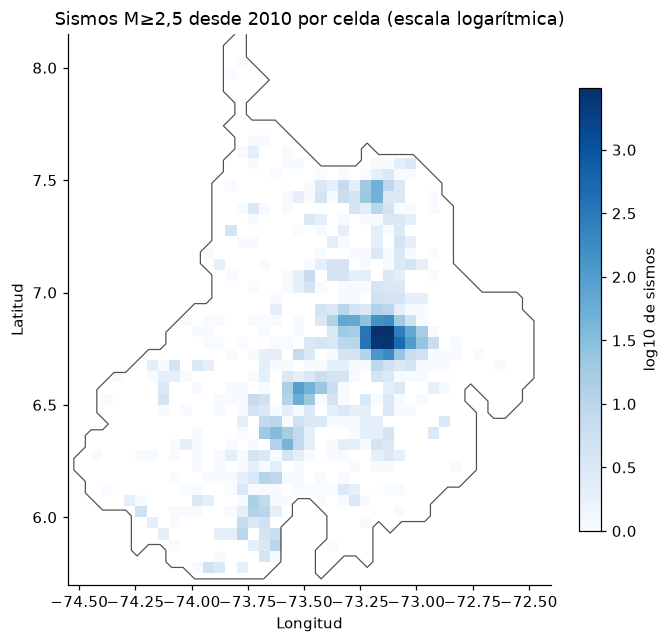

Celdas de Santander con algún sismo: 443 de 997
Las 30 celdas más activas concentran el 93% de los sismos del departamento


In [3]:
variables = clasificador.calcular_variables(homogeneo, grilla, n_ventanas)
total = variables["sismos_trimestre"].sum(axis=2)
permitida = np.isin(grilla["cell_id"].to_numpy(), clasificador.CELDAS_PERMITIDAS.to_numpy()).reshape(total.shape)
fig, eje = plt.subplots(figsize=(6.5, 6.5))
extension = (santander.LON_MIN, santander.LON_MIN + santander.N_COLUMNAS * clasificador.GRID_STEP, santander.LAT_MIN, santander.LAT_MIN + santander.N_FILAS * clasificador.GRID_STEP)
imagen = eje.imshow(np.where(permitida & (total > 0), np.log10(np.maximum(total, 1)), np.nan), origin="lower", extent=extension, cmap="Blues")
eje.contour(permitida.astype(float), levels=[0.5], colors="#52514e", linewidths=0.8, extent=extension)
eje.set(title="Sismos M≥2,5 desde 2010 por celda (escala logarítmica)", xlabel="Longitud", ylabel="Latitud"); eje.grid(False)
fig.colorbar(imagen, ax=eje, fraction=0.04, label="log10 de sismos"); plt.show()
ordenado = np.sort(total[permitida])[::-1]
print(f"Celdas de Santander con algún sismo: {(ordenado > 0).sum()} de {permitida.sum()}")
print(f"Las 30 celdas más activas concentran el {ordenado[:30].sum() / ordenado.sum():.0%} de los sismos del departamento")

**Qué se observa.** La sismicidad de Santander está muy concentrada: unas pocas celdas del nido acumulan casi todos los sismos y el resto del departamento tiene muy pocos. Eso condiciona todo el modelo.

## 2. Conjunto de datos

Una fila por celda y trimestre, con las mismas 15 variables del modelo 1 y la misma etiqueta: Bajo (ningún sismo en el trimestre siguiente), Medio (de 1 a 3) y Alto (más de 3).

In [4]:
santander.preparar_datos(homogeneo, grilla)
dataset = pd.read_csv(clasificador.DATASET_CSV)
print()
print("Valores faltantes:", int(dataset[clasificador.FEATURES + ["nivel_riesgo"]].isna().sum().sum()),
      " · Filas repetidas (misma celda y trimestre):", int(dataset.duplicated(["cell_id", "trimestre"]).sum()))
display(dataset.head(6))
display(dataset[clasificador.FEATURES].describe().T[["count", "mean", "std", "min", "50%", "max"]])

CLASIFICADOR DE RIESGO SÍSMICO POR ZONA - TODO SANTANDER · solo datos
   -> Sismos M>=2.5 desde 2010: 15,369
   -> Celdas en el rectángulo: 2,107   Dentro de Santander: 997   Con sismos en el entrenamiento: 358
   -> Casos (celda, trimestre): 22,554 con 15 variables
   -> Entrenamiento 15,752 casos  Bajo 14,446 (92%)  Medio 1,046 (7%)  Alto 260 (2%)
   -> Prueba         6,802 casos  Bajo 6,237 (92%)  Medio 431 (6%)  Alto 134 (2%)
   -> Conjunto de datos: C:\Users\Santiago\Documents\HACKATON UTS\entrenamiento\2_sismos_santander\data\processed\dataset_entrenamiento_santander.csv

Valores faltantes: 0  · Filas repetidas (misma celda y trimestre): 0


,cell_id,sismos_trimestre,sismos_ultimo_anio,sismos_promedio_historico,tendencia_sismos,sismos_vecinos_ultimo_anio,mag_media_ultimo_anio,mag_max_ultimo_anio,log_energia_ultimo_anio,prop_moderados_ultimo_anio,trimestres_desde_sismo_fuerte,prof_media_ultimo_anio,prof_std_ultimo_anio,dist_nido_km,lat_center,lon_center,trimestre,trimestre_objetivo,sismos_trimestre_siguiente,nivel_riesgo
0,54,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,67.000,0.000,0.000,145.823,5.775,-73.975,2010-T4,2011-T1,0.000,Bajo
1,55,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,67.000,0.000,0.000,142.448,5.775,-73.925,2010-T4,2011-T1,0.000,Bajo
2,56,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,67.000,0.000,0.000,139.211,5.775,-73.875,2010-T4,2011-T1,0.000,Bajo
3,58,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,67.000,0.000,0.000,133.186,5.775,-73.775,2010-T4,2011-T1,0.000,Bajo
4,103,0.000,1.000,0.250,-0.250,1.000,2.500,2.500,8.550,0.000,67.000,122.000,0.000,122.902,5.825,-73.675,2010-T4,2011-T1,1.000,Medio
5,145,0.000,0.000,0.000,0.000,3.000,0.000,0.000,0.000,0.000,67.000,0.000,0.000,120.826,5.875,-73.725,2010-T4,2011-T1,0.000,Bajo


,count,mean,std,min,50%,max
sismos_trimestre,"22,554.000",0.636,5.820,0.000,0.000,141.000
sismos_ultimo_anio,"22,554.000",2.550,22.315,0.000,0.000,435.000
sismos_promedio_historico,"22,554.000",0.621,4.516,0.000,0.034,64.659
tendencia_sismos,"22,554.000",-0.001,1.720,-49.000,0.000,52.500
sismos_vecinos_ultimo_anio,"22,554.000",19.939,91.164,0.000,1.000,914.000
mag_media_ultimo_anio,"22,554.000",0.604,1.193,0.000,0.000,5.000
mag_max_ultimo_anio,"22,554.000",0.652,1.309,0.000,0.000,6.400
log_energia_ultimo_anio,"22,554.000",1.996,3.928,0.000,0.000,14.400
prop_moderados_ultimo_anio,"22,554.000",0.024,0.136,0.000,0.000,1.000
trimestres_desde_sismo_fuerte,"22,554.000",61.920,15.794,0.000,67.000,67.000


,Entrenamiento,Prueba,Entrenamiento %,Prueba %
nivel_riesgo,,,,
Bajo,14446,6237,91.700,91.700
Medio,1046,431,6.600,6.300
Alto,260,134,1.700,2.000


Entrenamiento: 2011-T1 a 2021-T4   Prueba: 2022-T1 a 2026-T3


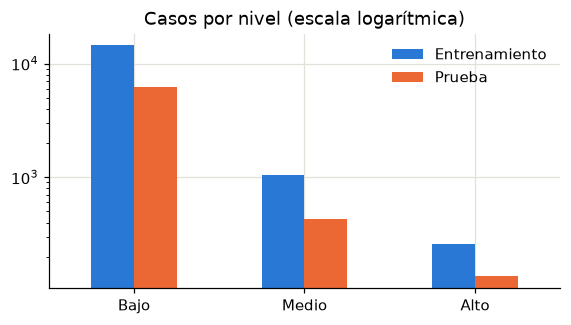

In [5]:
es_prueba = dataset["trimestre_objetivo"] >= "2022-T1"
reparto = pd.DataFrame({"Entrenamiento": dataset[~es_prueba]["nivel_riesgo"].value_counts(),
                        "Prueba": dataset[es_prueba]["nivel_riesgo"].value_counts()}).reindex(clasificador.NIVELES)
porcentajes = (100 * reparto / reparto.sum()).round(1).add_suffix(" %")
display(pd.concat([reparto, porcentajes], axis=1))
print(f"Entrenamiento: {dataset[~es_prueba]['trimestre_objetivo'].min()} a {dataset[~es_prueba]['trimestre_objetivo'].max()}"
      f"   Prueba: {dataset[es_prueba]['trimestre_objetivo'].min()} a {dataset[es_prueba]['trimestre_objetivo'].max()}")
fig, eje = plt.subplots(figsize=(6, 3))
reparto.plot.bar(ax=eje, color=[AZUL, NARANJA], rot=0, logy=True); eje.set(title="Casos por nivel (escala logarítmica)", xlabel=""); eje.legend(frameon=False); plt.show()

**Lo que hay que tener presente al entrenar.** Más del 90 % de los casos son de nivel Bajo. Un modelo que dijera siempre «Bajo» acertaría
más del 90 %, así que **la exactitud no sirve para juzgar este modelo**: habrá que mirar el F1 macro y el recall de los niveles Medio y Alto,
y compararlo con la regla de persistencia.

## 3. Entrenamiento

Se ejecuta el mismo proceso del modelo 1, con la grilla de Santander. Los ajustes del Random Forest (balanceo de clases y profundidad) se eligen
con validación dentro del periodo de entrenamiento (2017 a 2021), sin mirar la prueba. Lo que sigue es la salida completa del script.

In [6]:
clasificador.main()

CLASIFICADOR DE RIESGO SÍSMICO POR ZONA - TODO SANTANDER

1. Carga y limpieza del catálogo del SGC...


   -> Sismos en el catálogo:                 184,723
   -> Sismos M>=2.5 desde 2010 (homogéneo):   15,369 (15,369 en la zona y el resto en su margen)
   -> Trimestres completos: 67 (2010-T1 a 2026-T3)

2. Grilla e ingeniería de variables...


   -> Celdas de 0.05°: 2107 en la grilla, 358 con sismicidad
   -> Muestras (celda, trimestre): 22,554 con 15 variables

3. Etiqueta: nivel de actividad del trimestre siguiente...
   -> Bajo:  hasta 0 sismos M>=2.5 en el trimestre
   -> Medio: más de 0 y hasta 3
   -> Alto:  más de 3
   -> Entrenamiento 2011-T1 a 2021-T4: 15752 muestras  Bajo 14446  Medio 1046  Alto 260
   -> Prueba        2022-T1 a 2026-T3: 6802 muestras  Bajo 6237  Medio 431  Alto 134

4. Entrenamiento y evaluación en el periodo de prueba...


   -> Ajustes del Random Forest elegidos con validación interna (2017 a 2021): balanceo 0.5, profundidad 10
      balanceo 0.50  profundidad 10  ->  F1 macro 71.29%  exactitud 92.99%
      balanceo 0.75  profundidad  6  ->  F1 macro 70.60%  exactitud 91.72%
      balanceo 0.75  profundidad 10  ->  F1 macro 70.55%  exactitud 91.59%
      balanceo 0.50  profundidad  6  ->  F1 macro 70.42%  exactitud 92.97%



RESULTADOS EN EL PERIODO DE PRUEBA
Modelo                                Accuracy  F1 macro  Recall Alto
Base: clase más frecuente               91.69%    31.89%        0.00%
Base: igual al trimestre anterior       90.86%    70.00%       86.57%
Base: promedio del último año           82.99%    68.23%       93.28%
Regresión Logística                     84.11%    68.37%       97.76%
Random Forest                           93.44%    74.29%       89.55%

   -> Modelo elegido: Random Forest

   -> Techo de referencia (oráculo que conoce la tasa real de cada celda):
      Accuracy 94.16%, F1 macro 73.55%
      El modelo alcanza el 99% de esa exactitud; el error restante es sobre todo azar de los sismos.

REPORTE DE CLASIFICACIÓN (Random Forest):
              precision    recall  f1-score   support

        Bajo     0.9603    0.9743    0.9673      6237
       Medio     0.4938    0.3689    0.4223       431
        Alto     0.7895    0.8955    0.8392       134

    accuracy                  

   -> Riesgo predicho para 2026-T4: 2082 celdas en Bajo, 19 celdas en Medio, 6 celdas en Alto
   -> Dataset de entrenamiento: C:\Users\Santiago\Documents\HACKATON UTS\entrenamiento\2_sismos_santander\data\processed\dataset_entrenamiento_santander.csv
   -> Grilla con el riesgo:     C:\Users\Santiago\Documents\HACKATON UTS\entrenamiento\2_sismos_santander\data\processed\grilla_riesgo_santander.geojson
   -> Modelo:                   C:\Users\Santiago\Documents\HACKATON UTS\entrenamiento\2_sismos_santander\models\modelo_riesgo_sismico_santander.pkl
   -> Métricas:                 C:\Users\Santiago\Documents\HACKATON UTS\entrenamiento\2_sismos_santander\models\metricas_clasificador_santander.json
   -> Historial de la prueba:   C:\Users\Santiago\Documents\HACKATON UTS\entrenamiento\2_sismos_santander\models\historial_prueba_santander.json
PIPELINE COMPLETADO.


## 4. Resultados en el periodo de prueba

,Exactitud %,F1 macro %,Recall del nivel Alto %
Base: clase más frecuente,91.690,31.890,0.000
Base: igual al trimestre anterior,90.860,70.000,86.570
Base: promedio del último año,82.990,68.230,93.280
Regresión Logística,84.110,68.370,97.760
Random Forest,93.440,74.290,89.550
Techo de referencia (oráculo),94.160,73.550,91.790


Modelo elegido: Random Forest · Ajustes: {'balanceo': 0.5, 'profundidad': 10}
Casos de prueba: 6,802 (2022-T1 a 2026-T3)


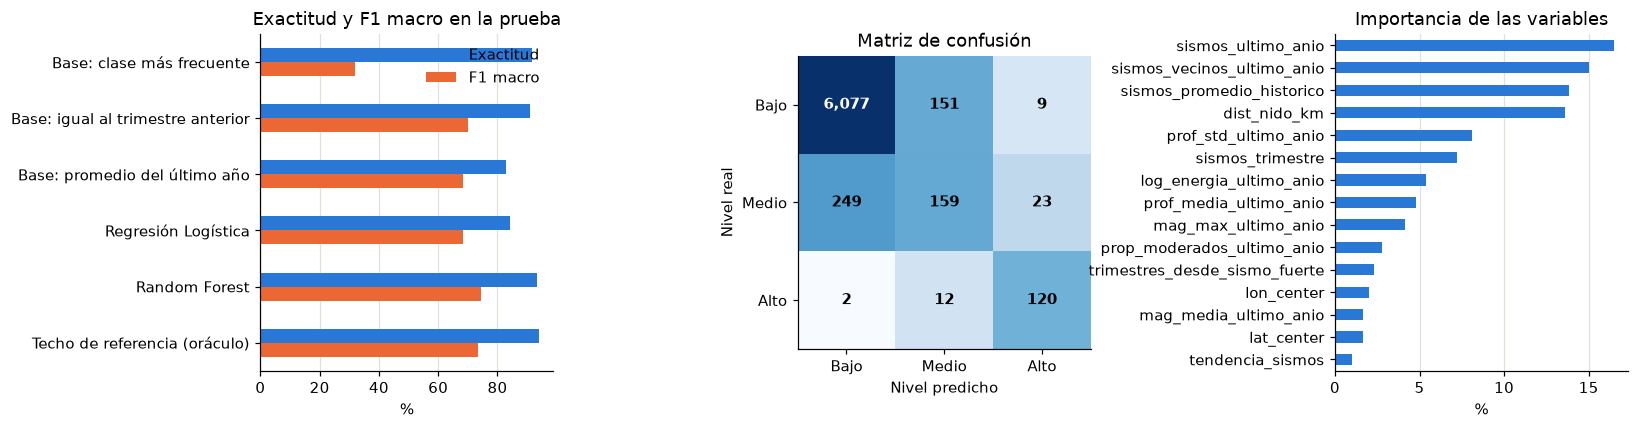

In [7]:
guardado = json.loads(clasificador.METRICAS_JSON.read_text(encoding="utf-8"))
resultados = pd.DataFrame(guardado["metricas"]).T
resultados.loc["Techo de referencia (oráculo)"] = guardado["techo_del_problema"]
display((100 * resultados).round(2).rename(columns={"accuracy": "Exactitud %", "f1_macro": "F1 macro %", "recall_alto": "Recall del nivel Alto %"}))
print("Modelo elegido:", guardado["modelo_elegido"], "· Ajustes:", {k: v for k, v in guardado["ajustes"].items() if k != "validacion_interna"})
print(f"Casos de prueba: {guardado['muestras_prueba']:,} ({guardado['periodo_prueba'][0]} a {guardado['periodo_prueba'][1]})")

matriz = np.array(guardado["matriz_confusion"]["valores"])
importancias = pd.Series(guardado["importancia_variables"]).sort_values()
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
(100 * resultados[["accuracy", "f1_macro"]]).plot.barh(ax=ejes[0], color=[AZUL, NARANJA]); ejes[0].invert_yaxis()
ejes[0].set(title="Exactitud y F1 macro en la prueba", xlabel="%"); ejes[0].legend(["Exactitud", "F1 macro"], frameon=False); ejes[0].grid(axis="y", visible=False)
ejes[1].imshow(np.log10(matriz + 1), cmap="Blues"); ejes[1].grid(False)
ejes[1].set(title="Matriz de confusión", xlabel="Nivel predicho", ylabel="Nivel real", xticks=range(3), yticks=range(3),
            xticklabels=clasificador.NIVELES, yticklabels=clasificador.NIVELES)
for a in range(3):
    for b in range(3):
        ejes[1].text(b, a, f"{matriz[a, b]:,}", ha="center", va="center", color="white" if matriz[a, b] > 1000 else "black", fontweight="bold")
(100 * importancias).plot.barh(ax=ejes[2], color=AZUL); ejes[2].set(title="Importancia de las variables", xlabel="%"); ejes[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

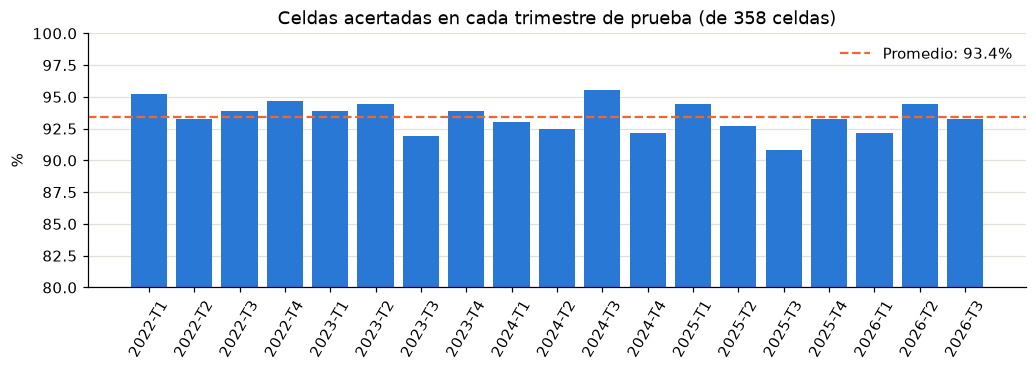

In [8]:
historial = json.loads(clasificador.HISTORIAL_JSON.read_text(encoding="utf-8"))
con_modelo = historial["celdas_con_modelo"]
aciertos = pd.Series({t["trimestre"]: sum(t["predicho"][c] == t["real"][c] for c in con_modelo) for t in historial["trimestres"]})
fig, eje = plt.subplots(figsize=(11, 3))
eje.bar(aciertos.index, 100 * aciertos / len(con_modelo), color=AZUL)
eje.axhline(100 * aciertos.mean() / len(con_modelo), color=NARANJA, linestyle="--", label=f"Promedio: {aciertos.mean() / len(con_modelo):.1%}")
eje.set(title=f"Celdas acertadas en cada trimestre de prueba (de {len(con_modelo)} celdas)", ylabel="%", ylim=(80, 100)); eje.tick_params(axis="x", rotation=60)
eje.grid(axis="x", visible=False); eje.legend(frameon=False); plt.show()

**Cómo leer estos resultados.**

- **La exactitud es alta, pero engaña:** decir siempre «Bajo» ya acierta cerca del 92 %. Lo que importa es el **F1 macro**, que pesa por igual los tres niveles, y el recall del nivel Alto.
- **El Random Forest supera a la regla de persistencia** («igual al trimestre anterior») tanto en exactitud como en F1 macro.
- **El nivel Medio es el más difícil**, igual que en el modelo 1: las celdas con uno a tres sismos por trimestre son las más sujetas al azar.
- **Este modelo no sustituye al de Los Santos.** Para esas 30 celdas predice mejor el modelo 1, entrenado solo con ellas.